<a href="https://colab.research.google.com/github/YeweonJung/workshop/blob/main/%EC%97%B0%EC%86%8D%ED%98%95_%EB%B3%80%EC%88%98%EC%9D%98_%ED%9A%A8%EA%B3%BC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EMM · Contrast · Interaction 실습

## 1. 가상 자료 만들기


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from patsy import build_design_matrices
from IPython.display import display

rng = np.random.default_rng(42)
groups = ['Placebo', 'Low', 'High']
female_n = [20, 60, 100]  # 각 군 120명 중 여성 수
effects = [0, -5, -10]
interaction = -8  # 0으로 바꾸면 생성 모형의 교호작용이 사라집니다
parts = []
for group, nf, effect in zip(groups, female_n, effects):
    sex = np.array(['F'] * nf + ['M'] * (120 - nf))
    mu = 80 + effect + 12 * (sex == 'M')
    mu = mu + interaction * (group == 'High') * (sex == 'M')
    parts.append(pd.DataFrame({'Treatment': group, 'Sex': sex,
                               'PANSS': mu + rng.normal(0, 10, 120)}))
df = pd.concat(parts, ignore_index=True)
display(pd.crosstab(df.Treatment, df.Sex).reindex(groups))
display(df.head())

Sex,F,M
Treatment,,
Placebo,20,100
Low,60,60
High,100,20


,Treatment,Sex,PANSS
0,Placebo,F,83.047171
1,Placebo,F,69.600159
2,Placebo,F,87.504512
3,Placebo,F,89.405647
4,Placebo,F,60.489648


## 2. 단순 평균 vs EMM


,Estimate,Lower,Upper,Raw_mean
Placebo,85.51,83.22,87.79,89.40
Low,80.66,78.96,82.37,80.66
High,72.44,70.15,74.72,71.33


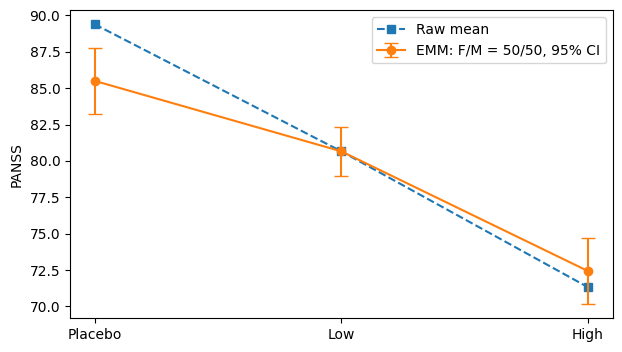

In [ ]:
import statsmodels.api as sm
from patsy import dmatrices

def fit_model(formula, data):
    y, x = dmatrices(formula, data, return_type='dataframe')
    result = sm.OLS(y, x).fit()
    result.design_spec = x.design_info
    return result

def design(model, grid):
    return np.asarray(build_design_matrices([model.design_spec], grid)[0])

model = fit_model('PANSS ~ Treatment * Sex', df)

# 평균이나 차이의 표준오차는 회귀계수의 공분산까지 반영합니다.
def estimate(model, rows, names, adjust=False):
    test = model.t_test(np.atleast_2d(rows))
    m = len(names) if adjust else 1
    ci = test.conf_int(alpha=0.05 / m)
    return pd.DataFrame({'Estimate': np.ravel(test.effect),
                         'Lower': ci[:, 0], 'Upper': ci[:, 1],
                         'p': np.ravel(test.pvalue),
                         'p_adjusted': np.minimum(np.ravel(test.pvalue) * m, 1)}, index=names)

grid = pd.DataFrame([(g, s) for g in groups for s in ['F', 'M']],
                    columns=['Treatment', 'Sex'])
X = design(model, grid)
L = X.reshape(3, 2, -1).mean(axis=1)  # Placebo, Low, High × 50:50 성별
emm = estimate(model, L, groups)[['Estimate', 'Lower', 'Upper']]
raw = df.groupby('Treatment').PANSS.mean().reindex(groups)
display(emm.assign(Raw_mean=raw).round(2))
plt.figure(figsize=(7, 4))
plt.plot(groups, raw, 's--', label='Raw mean')
plt.errorbar(groups, emm.Estimate.to_numpy(),
             yerr=np.array([emm.Estimate-emm.Lower, emm.Upper-emm.Estimate]),
             fmt='o-', capsize=5, label='EMM: F/M = 50/50, 95% CI')
plt.ylabel('PANSS')
plt.legend()
plt.show()

## 3. Pairwise · Reference · Custom contrast


Pairwise: Bonferroni, 3 tests


,Estimate,Lower,Upper,p,p_adjusted
Low - Placebo,-4.842020,-8.330621,-1.353420,9.315298e-04,2.794589e-03
High - Placebo,-13.068179,-17.023879,-9.112478,2.586177e-14,7.758530e-14
High - Low,-8.226158,-11.714758,-4.737558,2.935993e-08,8.807980e-08


Reference: Bonferroni, 2 tests


,Estimate,Lower,Upper,p,p_adjusted
Low - Placebo,-4.842020,-8.106642,-1.577399,9.315298e-04,1.863060e-03
High - Placebo,-13.068179,-16.769912,-9.366445,2.586177e-14,5.172354e-14


Custom: 1 preplanned test


,Estimate,Lower,Upper,p,p_adjusted
Average drug - Placebo,-8.9551,-11.650282,-6.259917,2.224266e-10,2.224266e-10


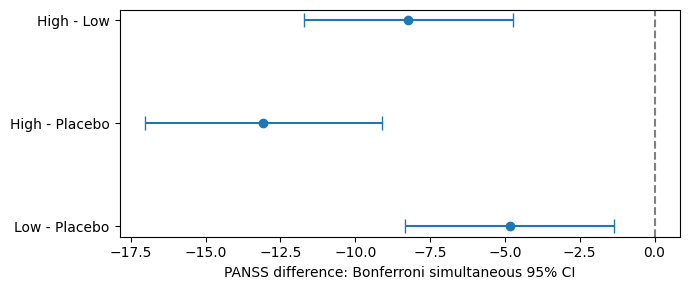

In [ ]:
pair_weights = np.array([[-1, 1, 0], [-1, 0, 1], [0, -1, 1]])
pairwise = estimate(model, pair_weights @ L,
                    ['Low - Placebo', 'High - Placebo', 'High - Low'], adjust=True)
reference = estimate(model, pair_weights[:2] @ L,
                     ['Low - Placebo', 'High - Placebo'], adjust=True)
custom = estimate(model, np.array([-1, 0.5, 0.5]) @ L,
                  ['Average drug - Placebo'])
print('Pairwise: Bonferroni, 3 tests')
display(pairwise)
print('Reference: Bonferroni, 2 tests')
display(reference)
print('Custom: 1 preplanned test')
display(custom)
plt.figure(figsize=(7, 3))
plt.errorbar(pairwise.Estimate.to_numpy(), pairwise.index,
             xerr=np.array([pairwise.Estimate-pairwise.Lower, pairwise.Upper-pairwise.Estimate]),
             fmt='o', capsize=5)
plt.axvline(0, color='gray', linestyle='--')
plt.xlabel('PANSS difference: Bonferroni simultaneous 95% CI')
plt.tight_layout()
plt.show()

## 4. Interaction: 성별에 따라 치료군 차이가 다른가?


Interaction: F(2, 354) = 5.255, p = 0.005636


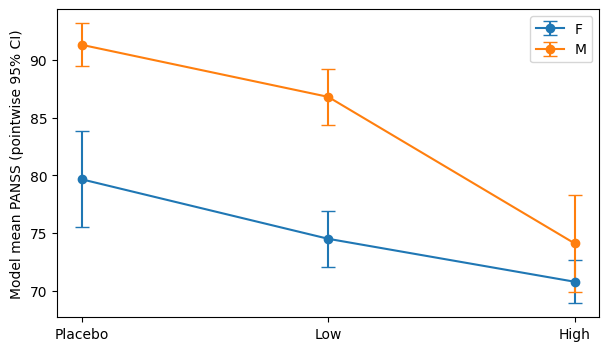

In [ ]:
reduced = fit_model('PANSS ~ Treatment + Sex', df)
f, p, df_diff = model.compare_f_test(reduced)
print(f'Interaction: F({df_diff:.0f}, {model.df_resid:.0f}) = {f:.3f}, p = {p:.4g}')
conditional = estimate(model, X, [f'{g}/{s}' for g, s in grid.to_numpy()])
plt.figure(figsize=(7, 4))
for offset, sex in enumerate(['F', 'M']):
    r = conditional.iloc[offset::2]
    plt.errorbar(groups, r.Estimate.to_numpy(),
                 yerr=np.array([r.Estimate-r.Lower, r.Upper-r.Estimate]),
                 fmt='o-', capsize=5, label=sex)
plt.ylabel('Model mean PANSS (pointwise 95% CI)')
plt.legend()
plt.show()

## 5. Simple effects와 차이의 차이


,Estimate,Lower,Upper,p,p_adjusted
F: Low - Placebo,-5.165595,-11.320115,0.988924,3.580877e-02,1.432351e-01
F: High - Placebo,-8.894871,-14.733561,-3.056181,1.547458e-04,6.189834e-04
M: Low - Placebo,-4.518445,-8.410905,-0.625986,3.791792e-03,1.516717e-02
M: High - Placebo,-17.241486,-23.080176,-11.402796,9.149022e-13,3.659609e-12


Preplanned interaction contrast: (High - Placebo) M minus F


,Estimate,Lower,Upper,p,p_adjusted
Difference of differences,-8.346615,-14.815054,-1.878177,0.011585,0.011585


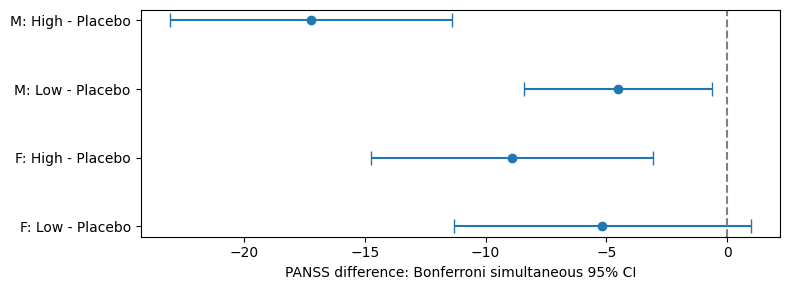

In [ ]:
simple_rows = [X[2]-X[0], X[4]-X[0], X[3]-X[1], X[5]-X[1]]
simple = estimate(model, simple_rows,
                  ['F: Low - Placebo', 'F: High - Placebo',
                   'M: Low - Placebo', 'M: High - Placebo'], adjust=True)
display(simple)
did = (X[5]-X[1]) - (X[4]-X[0])
print('Preplanned interaction contrast: (High - Placebo) M minus F')
display(estimate(model, did, ['Difference of differences']))
plt.figure(figsize=(8, 3))
plt.errorbar(simple.Estimate.to_numpy(), simple.index,
             xerr=np.array([simple.Estimate-simple.Lower, simple.Upper-simple.Estimate]),
             fmt='o', capsize=5)
plt.axvline(0, color='gray', linestyle='--')
plt.xlabel('PANSS difference: Bonferroni simultaneous 95% CI')
plt.tight_layout()
plt.show()

## 6. 연속형 변수: Dose × 기저 중증도
.

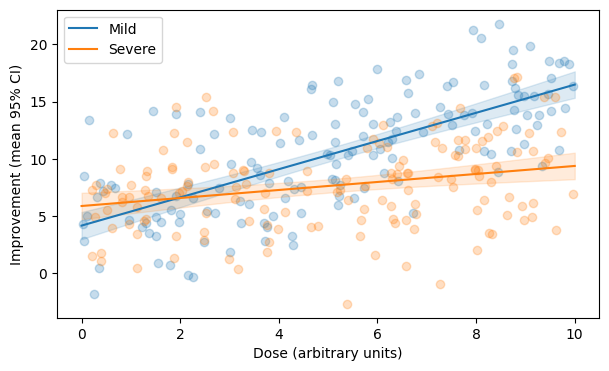

In [ ]:
rng = np.random.default_rng(7)
n = 300
slope_gap = -1.2  # 0으로 바꾸면 두 군의 생성 기울기가 같아집니다
dose = rng.uniform(0, 10, n)
severity = np.repeat(['Mild', 'Severe'], n // 2)
severe = severity == 'Severe'
dose_df = pd.DataFrame({'Dose': dose, 'Severity': severity,
    'Improvement': 3 + 4*severe + (1.5 + slope_gap*severe)*dose + rng.normal(0, 4, n)})
slope_model = fit_model('Improvement ~ Dose * Severity', dose_df)
plt.figure(figsize=(7, 4))
for group, color in [('Mild', 'tab:blue'), ('Severe', 'tab:orange')]:
    d = dose_df[dose_df.Severity == group]
    plt.scatter(d.Dose, d.Improvement, alpha=0.25, color=color)
    pred_grid = pd.DataFrame({'Dose': np.linspace(0, 10, 100), 'Severity': group})
    pred = slope_model.get_prediction(design(slope_model, pred_grid), transform=False).summary_frame()
    plt.plot(pred_grid.Dose, pred['mean'], color=color, label=group)
    plt.fill_between(pred_grid.Dose.to_numpy(), pred.mean_ci_lower.to_numpy(),
                     pred.mean_ci_upper.to_numpy(), color=color, alpha=0.15)
plt.xlabel('Dose (arbitrary units)')
plt.ylabel('Improvement (mean 95% CI)')
plt.legend()
plt.show()

## 7. Simple slopes와 기울기 차이 검정


In [ ]:
slope_grid = pd.DataFrame({'Dose': [0, 1, 0, 1],
                           'Severity': ['Mild', 'Mild', 'Severe', 'Severe']})
D = design(slope_model, slope_grid)
slopes = np.array([D[1]-D[0], D[3]-D[2]])
print('Simple slopes: Bonferroni, 2 tests')
display(estimate(slope_model, slopes, ['Mild slope', 'Severe slope'], adjust=True))
print('Interaction: Severe slope - Mild slope')
display(estimate(slope_model, slopes[1]-slopes[0], ['Slope difference']))

Simple slopes: Bonferroni, 2 tests


,Estimate,Lower,Upper,p,p_adjusted
Mild slope,1.232059,0.999349,1.464769,4.799574e-27,9.599148e-27
Severe slope,0.350050,0.121212,0.578889,6.509249e-04,1.301850e-03


Interaction: Severe slope - Mild slope


,Estimate,Lower,Upper,p,p_adjusted
Slope difference,-0.882009,-1.167118,-0.5969,3.534922e-09,3.534922e-09
